In [174]:
pd.set_option('display.max_columns', None)
#pd.set_option('display.max_rows', None)
pd.reset_option('display.max_rows')

In [175]:
# Loading CSV

In [176]:
#Two datasets will be used in this project, borrower profiles dataset and loan application dataset.
# Borrower profile dataset will be used directly to inform changes to their credit scoring model while loan appliaction dataset will be used to find the loan approval thresholds.

In [177]:
df = pd.read_csv("borrower_profiles.csv")
df

,borrower_id,age,state,education_level,employment_status,years_employed,annual_income,credit_score,home_ownership,dependents,existing_monthly_debt
0,BRW-0001,62,CT,High School,Self-Employed,6,31020,596,Rent,1,892
1,BRW-0002,24,CO,High School,Full-Time,4,40188,543,Own,2,869
2,BRW-0003,50,NC,Bachelor,Contract,22,41014,611,Mortgage,0,1806
3,BRW-0004,43,TX,High School,Full-Time,19,35036,701,Mortgage,2,928
4,BRW-0005,46,NY,High School,Full-Time,18,44528,715,Own,0,608
...,...,...,...,...,...,...,...,...,...,...,...
495,BRW-0496,27,IL,Bachelor,Contract,4,60337,661,Mortgage,0,2359
496,BRW-0497,23,MO,High School,Full-Time,3,54617,773,Rent,3,1475
497,BRW-0498,30,CO,Doctorate,Self-Employed,7,85000,845,Mortgage,3,1894
498,BRW-0499,62,MA,Bachelor,Full-Time,14,62749,811,Rent,1,1339


In [178]:
# Finding how many of the missing vales exists 

In [179]:
df.isnull().sum()

borrower_id              0
age                      0
state                    0
education_level          0
employment_status        0
years_employed           0
annual_income            0
credit_score             0
home_ownership           0
dependents               0
existing_monthly_debt    0
dtype: int64

In [180]:
# Finding shape of borrowers data

In [181]:
df.shape

(500, 11)

In [182]:
# Finding information on borrower datasets

In [183]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   borrower_id            500 non-null    object
 1   age                    500 non-null    int64 
 2   state                  500 non-null    object
 3   education_level        500 non-null    object
 4   employment_status      500 non-null    object
 5   years_employed         500 non-null    int64 
 6   annual_income          500 non-null    int64 
 7   credit_score           500 non-null    int64 
 8   home_ownership         500 non-null    object
 9   dependents             500 non-null    int64 
 10  existing_monthly_debt  500 non-null    int64 
dtypes: int64(6), object(5)
memory usage: 43.1+ KB


In [184]:
# Describing our borrower dataset

In [185]:
df.describe()

,age,years_employed,annual_income,credit_score,dependents,existing_monthly_debt
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,44.986000,10.854000,64471.484000,704.952000,1.356000,1585.166000
std,13.539736,9.301706,28959.837645,97.339157,1.252358,1089.979915
min,22.000000,0.000000,12549.000000,528.000000,0.000000,124.000000
25%,33.000000,3.000000,42968.250000,617.750000,0.000000,788.750000
50%,45.000000,8.000000,59282.500000,708.000000,1.000000,1312.000000
75%,57.000000,17.000000,79780.500000,794.250000,2.000000,2131.750000
max,68.000000,35.000000,157047.000000,850.000000,4.000000,6130.000000


In [186]:
# Checking borrower data types

In [187]:
df.dtypes

borrower_id              object
age                       int64
state                    object
education_level          object
employment_status        object
years_employed            int64
annual_income             int64
credit_score              int64
home_ownership           object
dependents                int64
existing_monthly_debt     int64
dtype: object

In [188]:
df.select_dtypes(include = 'number')

,age,years_employed,annual_income,credit_score,dependents,existing_monthly_debt
0,62,6,31020,596,1,892
1,24,4,40188,543,2,869
2,50,22,41014,611,0,1806
3,43,19,35036,701,2,928
4,46,18,44528,715,0,608
...,...,...,...,...,...,...
495,27,4,60337,661,0,2359
496,23,3,54617,773,3,1475
497,30,7,85000,845,3,1894
498,62,14,62749,811,1,1339


In [189]:
df.select_dtypes(include = 'object')

,borrower_id,state,education_level,employment_status,home_ownership
0,BRW-0001,CT,High School,Self-Employed,Rent
1,BRW-0002,CO,High School,Full-Time,Own
2,BRW-0003,NC,Bachelor,Contract,Mortgage
3,BRW-0004,TX,High School,Full-Time,Mortgage
4,BRW-0005,NY,High School,Full-Time,Own
...,...,...,...,...,...
495,BRW-0496,IL,Bachelor,Contract,Mortgage
496,BRW-0497,MO,High School,Full-Time,Rent
497,BRW-0498,CO,Doctorate,Self-Employed,Mortgage
498,BRW-0499,MA,Bachelor,Full-Time,Rent


In [190]:
df.select_dtypes(include = 'float')

""
0
1
2
3
4
...
495
496
497
498


In [191]:
dataset = pd.read_csv("loan_applications.csv")
dataset

,loan_id,borrower_id,application_date,loan_purpose,loan_amount,term_months,interest_rate,monthly_payment,dti_ratio,loan_status,days_delinquent,defaulted
0,LN-00001,BRW-0001,2024-01-08,Vacation,16100.0,36,13.05,542.86,55.5,Paid Off,0,0
1,LN-00002,BRW-0001,2024-08-13,Major Purchase,5600.0,48,14.21,153.62,40.4,Default,138,1
2,LN-00003,BRW-0002,2025-06-28,Moving,44700.0,36,12.37,1492.59,70.5,Paid Off,0,0
3,LN-00004,BRW-0003,2025-05-18,Auto Loan,9200.0,48,11.18,238.58,59.8,Default,34,1
4,LN-00005,BRW-0004,2025-03-24,Moving,11200.0,36,9.66,359.61,44.1,Current,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
596,LN-00597,BRW-0497,2025-02-06,Wedding,29100.0,36,7.38,903.59,52.3,Default,31,1
597,LN-00598,BRW-0498,2024-04-19,Moving,4600.0,12,7.27,398.60,32.4,Current,0,0
598,LN-00599,BRW-0499,2024-02-24,Education,7800.0,60,9.86,165.19,28.8,Current,0,0
599,LN-00600,BRW-0500,2024-11-14,Medical Expenses,26400.0,24,11.44,1235.85,73.2,Late,15,0


In [192]:
# Finding how many of the missing values exists

In [193]:
dataset.isnull().sum()

loan_id             0
borrower_id         0
application_date    0
loan_purpose        0
loan_amount         0
term_months         0
interest_rate       0
monthly_payment     0
dti_ratio           0
loan_status         0
days_delinquent     0
defaulted           0
dtype: int64

In [194]:
# Finding shape of loan applications dataset

In [195]:
dataset.shape

(601, 12)

In [196]:
# Finding information on loan applications dataset

In [197]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 601 entries, 0 to 600
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   loan_id           601 non-null    object 
 1   borrower_id       601 non-null    object 
 2   application_date  601 non-null    object 
 3   loan_purpose      601 non-null    object 
 4   loan_amount       601 non-null    float64
 5   term_months       601 non-null    int64  
 6   interest_rate     601 non-null    float64
 7   monthly_payment   601 non-null    float64
 8   dti_ratio         601 non-null    float64
 9   loan_status       601 non-null    object 
 10  days_delinquent   601 non-null    int64  
 11  defaulted         601 non-null    int64  
dtypes: float64(4), int64(3), object(5)
memory usage: 56.5+ KB


In [198]:
# Describing our loan aplications dataset

In [199]:
dataset.describe()

,loan_amount,term_months,interest_rate,monthly_payment,dti_ratio,days_delinquent,defaulted
count,601.000000,601.000000,601.000000,601.000000,601.000000,601.000000,601.000000
mean,22148.252912,36.539101,10.641331,948.337654,49.680699,27.036606,0.242928
std,13215.261422,16.898192,2.251153,864.959543,24.113652,47.802845,0.429209
min,2000.000000,12.000000,5.860000,44.140000,7.600000,0.000000,0.000000
25%,10900.000000,24.000000,8.940000,359.860000,32.200000,0.000000,0.000000
50%,20400.000000,36.000000,10.540000,684.870000,48.100000,0.000000,0.000000
75%,32700.000000,48.000000,12.330000,1165.200000,62.400000,30.000000,0.000000
max,49800.000000,60.000000,15.860000,4262.690000,177.400000,180.000000,1.000000


In [200]:
# Checking loan applications dataset

In [201]:
dataset.dtypes

loan_id              object
borrower_id          object
application_date     object
loan_purpose         object
loan_amount         float64
term_months           int64
interest_rate       float64
monthly_payment     float64
dti_ratio           float64
loan_status          object
days_delinquent       int64
defaulted             int64
dtype: object

In [202]:
dataset.select_dtypes(include = 'number')

,loan_amount,term_months,interest_rate,monthly_payment,dti_ratio,days_delinquent,defaulted
0,16100.0,36,13.05,542.86,55.5,0,0
1,5600.0,48,14.21,153.62,40.4,138,1
2,44700.0,36,12.37,1492.59,70.5,0,0
3,9200.0,48,11.18,238.58,59.8,34,1
4,11200.0,36,9.66,359.61,44.1,0,0
...,...,...,...,...,...,...,...
596,29100.0,36,7.38,903.59,52.3,31,1
597,4600.0,12,7.27,398.60,32.4,0,0
598,7800.0,60,9.86,165.19,28.8,0,0
599,26400.0,24,11.44,1235.85,73.2,15,0


In [203]:
dataset.select_dtypes(include = 'object')

,loan_id,borrower_id,application_date,loan_purpose,loan_status
0,LN-00001,BRW-0001,2024-01-08,Vacation,Paid Off
1,LN-00002,BRW-0001,2024-08-13,Major Purchase,Default
2,LN-00003,BRW-0002,2025-06-28,Moving,Paid Off
3,LN-00004,BRW-0003,2025-05-18,Auto Loan,Default
4,LN-00005,BRW-0004,2025-03-24,Moving,Current
...,...,...,...,...,...
596,LN-00597,BRW-0497,2025-02-06,Wedding,Default
597,LN-00598,BRW-0498,2024-04-19,Moving,Current
598,LN-00599,BRW-0499,2024-02-24,Education,Current
599,LN-00600,BRW-0500,2024-11-14,Medical Expenses,Late


In [204]:
dataset.select_dtypes(include = 'float')

,loan_amount,interest_rate,monthly_payment,dti_ratio
0,16100.0,13.05,542.86,55.5
1,5600.0,14.21,153.62,40.4
2,44700.0,12.37,1492.59,70.5
3,9200.0,11.18,238.58,59.8
4,11200.0,9.66,359.61,44.1
...,...,...,...,...
596,29100.0,7.38,903.59,52.3
597,4600.0,7.27,398.60,32.4
598,7800.0,9.86,165.19,28.8
599,26400.0,11.44,1235.85,73.2


In [205]:
# Joining the two datasets

In [206]:
df1 = pd.read_csv("borrower_profiles.csv")
df2 = pd.read_csv("loan_applications.csv")
display(df1.head(), df2.head())

,borrower_id,age,state,education_level,employment_status,years_employed,annual_income,credit_score,home_ownership,dependents,existing_monthly_debt
0,BRW-0001,62,CT,High School,Self-Employed,6,31020,596,Rent,1,892
1,BRW-0002,24,CO,High School,Full-Time,4,40188,543,Own,2,869
2,BRW-0003,50,NC,Bachelor,Contract,22,41014,611,Mortgage,0,1806
3,BRW-0004,43,TX,High School,Full-Time,19,35036,701,Mortgage,2,928
4,BRW-0005,46,NY,High School,Full-Time,18,44528,715,Own,0,608


,loan_id,borrower_id,application_date,loan_purpose,loan_amount,term_months,interest_rate,monthly_payment,dti_ratio,loan_status,days_delinquent,defaulted
0,LN-00001,BRW-0001,2024-01-08,Vacation,16100.0,36,13.05,542.86,55.5,Paid Off,0,0
1,LN-00002,BRW-0001,2024-08-13,Major Purchase,5600.0,48,14.21,153.62,40.4,Default,138,1
2,LN-00003,BRW-0002,2025-06-28,Moving,44700.0,36,12.37,1492.59,70.5,Paid Off,0,0
3,LN-00004,BRW-0003,2025-05-18,Auto Loan,9200.0,48,11.18,238.58,59.8,Default,34,1
4,LN-00005,BRW-0004,2025-03-24,Moving,11200.0,36,9.66,359.61,44.1,Current,0,0


In [207]:
# Merging borrower profiles and loan applications on borrower_id

In [208]:
df3 = pd.merge(df1, df2)
df3

,borrower_id,age,state,education_level,employment_status,years_employed,annual_income,credit_score,home_ownership,dependents,existing_monthly_debt,loan_id,application_date,loan_purpose,loan_amount,term_months,interest_rate,monthly_payment,dti_ratio,loan_status,days_delinquent,defaulted
0,BRW-0001,62,CT,High School,Self-Employed,6,31020,596,Rent,1,892,LN-00001,2024-01-08,Vacation,16100.0,36,13.05,542.86,55.5,Paid Off,0,0
1,BRW-0001,62,CT,High School,Self-Employed,6,31020,596,Rent,1,892,LN-00002,2024-08-13,Major Purchase,5600.0,48,14.21,153.62,40.4,Default,138,1
2,BRW-0002,24,CO,High School,Full-Time,4,40188,543,Own,2,869,LN-00003,2025-06-28,Moving,44700.0,36,12.37,1492.59,70.5,Paid Off,0,0
3,BRW-0003,50,NC,Bachelor,Contract,22,41014,611,Mortgage,0,1806,LN-00004,2025-05-18,Auto Loan,9200.0,48,11.18,238.58,59.8,Default,34,1
4,BRW-0004,43,TX,High School,Full-Time,19,35036,701,Mortgage,2,928,LN-00005,2025-03-24,Moving,11200.0,36,9.66,359.61,44.1,Current,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
596,BRW-0497,23,MO,High School,Full-Time,3,54617,773,Rent,3,1475,LN-00597,2025-02-06,Wedding,29100.0,36,7.38,903.59,52.3,Default,31,1
597,BRW-0498,30,CO,Doctorate,Self-Employed,7,85000,845,Mortgage,3,1894,LN-00598,2024-04-19,Moving,4600.0,12,7.27,398.60,32.4,Current,0,0
598,BRW-0499,62,MA,Bachelor,Full-Time,14,62749,811,Rent,1,1339,LN-00599,2024-02-24,Education,7800.0,60,9.86,165.19,28.8,Current,0,0
599,BRW-0500,31,MO,Associate,Full-Time,5,67070,604,Mortgage,0,2856,LN-00600,2024-11-14,Medical Expenses,26400.0,24,11.44,1235.85,73.2,Late,15,0


In [209]:
# 2. Segment Analysis

In [210]:
# Credit Score Buckets 

In [242]:
# Creat bins and category label
credit_bins   = [0, 599, 649, 699, 749, 850]
credit_labels = ['520–599', '600–649', '650–699', '700-749', '750+']

df3['credit_score_bucket'] = pd.cut(
    df3['credit_score'], bins = credit_bins, labels = credit_labels
)

credit_analysis = (
    df3.groupby('credit_score_bucket', observed = True)
    .agg(
        total_loans = ('loan_status', 'count'),
        defaults    = ('loan_status', lambda x: (x == 'Default').sum())
    )
    .assign(
        default_rate = lambda x: (x['defaults'] / x['total_loans'] * 100).round(2)
    )
)

print("Credit Score Segment Analysis")
display(credit_analysis)                    

Credit Score Segment Analysis


,total_loans,defaults,default_rate
credit_score_bucket,,,
520–599,116,57,49.14
600–649,93,27,29.03
650–699,75,21,28.00
700-749,86,14,16.28
750+,231,27,11.69


In [336]:
df3.head(10)

,borrower_id,age,state,education_level,employment_status,years_employed,annual_income,credit_score,home_ownership,dependents,existing_monthly_debt,loan_id,application_date,loan_purpose,loan_amount,term_months,interest_rate,monthly_payment,dti_ratio,loan_status,days_delinquent,defaulted,credit_score_bucket,dti_range
0,BRW-0001,62,CT,High School,Self-Employed,6,31020,596,Rent,1,892,LN-00001,2024-01-08,Vacation,16100.0,36,13.05,542.86,55.5,Paid Off,0,0,520–599,50%+
1,BRW-0001,62,CT,High School,Self-Employed,6,31020,596,Rent,1,892,LN-00002,2024-08-13,Major Purchase,5600.0,48,14.21,153.62,40.4,Default,138,1,520–599,35-50%
2,BRW-0002,24,CO,High School,Full-Time,4,40188,543,Own,2,869,LN-00003,2025-06-28,Moving,44700.0,36,12.37,1492.59,70.5,Paid Off,0,0,520–599,50%+
3,BRW-0003,50,NC,Bachelor,Contract,22,41014,611,Mortgage,0,1806,LN-00004,2025-05-18,Auto Loan,9200.0,48,11.18,238.58,59.8,Default,34,1,600–649,50%+
4,BRW-0004,43,TX,High School,Full-Time,19,35036,701,Mortgage,2,928,LN-00005,2025-03-24,Moving,11200.0,36,9.66,359.61,44.1,Current,0,0,700-749,35-50%
5,BRW-0005,46,NY,High School,Full-Time,18,44528,715,Own,0,608,LN-00006,2025-04-19,Education,28600.0,48,13.07,768.26,37.1,Current,0,0,700-749,35-50%
6,BRW-0006,40,OR,Doctorate,Contract,8,157047,749,Mortgage,1,3076,LN-00007,2024-07-04,Medical Expenses,39200.0,12,10.23,3450.50,49.9,Paid Off,0,0,700-749,35-50%
7,BRW-0007,35,GA,Bachelor,Self-Employed,5,84210,576,Mortgage,0,1682,LN-00008,2025-03-29,Home Improvement,36300.0,48,14.26,996.69,38.2,Default,38,1,520–599,35-50%
8,BRW-0007,35,GA,Bachelor,Self-Employed,5,84210,576,Mortgage,0,1682,LN-00009,2024-08-01,Business Loan,39000.0,60,13.73,902.01,36.8,Current,0,0,520–599,35-50%
9,BRW-0008,62,KY,Bachelor,Full-Time,14,61289,563,Rent,1,939,LN-00010,2024-11-01,Debt Consolidation,28400.0,12,11.88,2521.71,67.8,Default,43,1,520–599,50%+


In [213]:
## Instruption just curious how to finding for the data values 

In [214]:
(df3['loan_status'] == 'Default').sum()

np.int64(146)

In [215]:
df3['loan_status'].count()

np.int64(601)

In [216]:
(df3['loan_status'] == 'Paid Off').sum()

np.int64(113)

In [217]:
(df3['loan_status'] == 'Current').sum()

np.int64(239)

In [218]:
(df3['loan_status'] == 'Late').sum()

np.int64(103)

In [219]:
df3['loan_status'].unique()

array(['Paid Off', 'Default', 'Current', 'Late'], dtype=object)

In [220]:
df3['loan_status'].nunique()

4

In [221]:
df3['loan_status'].value_counts()

loan_status
Current     239
Default     146
Paid Off    113
Late        103
Name: count, dtype: int64

In [232]:
# DTI Range Analysis
# Create bins and category labels for DTI

In [255]:
dti_bins = [0, 20, 35, 50, np.inf]
dti_labels = ['<20%', '20-35%', '35-50%', '50%+']

df3['dti_range'] = pd.cut(
    df3['dti_ratio'], bins = dti_bins, labels = dti_labels, right = False
)

dti_analysis = (
    df3.groupby('dti_range', observed = True)
    .agg(
        total_loans = ('loan_status', 'count'),
        defaults    = ('loan_status', lambda x: (x == 'Default').sum())
    )
    .assign(
        default_rate = lambda x: (x['defaults'] / x['total_loans'] * 100).round(2)
    )
)

print("DTI Range Segment Analysis")
display(dti_analysis)

DTI Range Segment Analysis


,total_loans,defaults,default_rate
dti_range,,,
<20%,48,8,16.67
20-35%,132,14,10.61
35-50%,150,31,20.67
50%+,271,93,34.32


In [240]:
# Employment Status Analysis
# Grouping and Aggregating by Employment Status

In [241]:
employment_analysis = (
     df3.groupby('employment_status', observed = True)
    .agg(
        total_loans = ('loan_status', 'count'),
        defaults    = ('loan_status', lambda x: (x == 'Default').sum())
    )
    .assign(
        default_rate = lambda x: (x['defaults'] / x['total_loans'] * 100).round(2)
    )
)

print("Employement Status Analysis")
display(employment_analysis)

Employement Status Analysis


,total_loans,defaults,default_rate
employment_status,,,
Contract,66,15,22.73
Full-Time,305,73,23.93
Part-Time,65,18,27.69
Retired,60,14,23.33
Self-Employed,105,26,24.76


In [245]:
# Loan Purpose Segment Analysis
# Grouping and Aggregating by Loan Purpose

In [246]:
purpose_analysis = (
     df3.groupby('loan_purpose', observed = True)
    .agg(
        total_loans = ('loan_status', 'count'),
        defaults    = ('loan_status', lambda x: (x == 'Default').sum())
    )
    .assign(
        default_rate = lambda x: (x['defaults'] / x['total_loans'] * 100).round(2)
    )
)

print("Loan Purpose Segment Analysis")
display(purpose_analysis)

Loan Purpose Segment Analysis


,total_loans,defaults,default_rate
loan_purpose,,,
Auto Loan,59,16,27.12
Business Loan,58,14,24.14
Debt Consolidation,51,11,21.57
Education,53,12,22.64
Home Improvement,70,20,28.57
Major Purchase,68,15,22.06
Medical Expenses,68,14,20.59
Moving,56,12,21.43
Vacation,62,14,22.58


In [ ]:
# Combined Summary

In [258]:
all_segments = {
    "Credit Score": credit_analysis,
    "DTI": dti_analysis,
    "Employment": employment_analysis,
    "Loan Purpose": purpose_analysis,
}

for segment_name, result in all_segments.items():
    print(f"\n=== {segment_name} Segment Analysis ===")
    display(result)


=== Credit Score Segment Analysis ===


,total_loans,defaults,default_rate
credit_score_bucket,,,
520–599,116,57,49.14
600–649,93,27,29.03
650–699,75,21,28.00
700-749,86,14,16.28
750+,231,27,11.69



=== DTI Segment Analysis ===


,total_loans,defaults,default_rate
dti_range,,,
<20%,48,8,16.67
20-35%,132,14,10.61
35-50%,150,31,20.67
50%+,271,93,34.32



=== Employment Segment Analysis ===


,total_loans,defaults,default_rate
employment_status,,,
Contract,66,15,22.73
Full-Time,305,73,23.93
Part-Time,65,18,27.69
Retired,60,14,23.33
Self-Employed,105,26,24.76



=== Loan Purpose Segment Analysis ===


,total_loans,defaults,default_rate
loan_purpose,,,
Auto Loan,59,16,27.12
Business Loan,58,14,24.14
Debt Consolidation,51,11,21.57
Education,53,12,22.64
Home Improvement,70,20,28.57
Major Purchase,68,15,22.06
Medical Expenses,68,14,20.59
Moving,56,12,21.43
Vacation,62,14,22.58


In [261]:
df3

,borrower_id,age,state,education_level,employment_status,years_employed,annual_income,credit_score,home_ownership,dependents,existing_monthly_debt,loan_id,application_date,loan_purpose,loan_amount,term_months,interest_rate,monthly_payment,dti_ratio,loan_status,days_delinquent,defaulted,credit_score_bucket,dti_range
0,BRW-0001,62,CT,High School,Self-Employed,6,31020,596,Rent,1,892,LN-00001,2024-01-08,Vacation,16100.0,36,13.05,542.86,55.5,Paid Off,0,0,520–599,50%+
1,BRW-0001,62,CT,High School,Self-Employed,6,31020,596,Rent,1,892,LN-00002,2024-08-13,Major Purchase,5600.0,48,14.21,153.62,40.4,Default,138,1,520–599,35-50%
2,BRW-0002,24,CO,High School,Full-Time,4,40188,543,Own,2,869,LN-00003,2025-06-28,Moving,44700.0,36,12.37,1492.59,70.5,Paid Off,0,0,520–599,50%+
3,BRW-0003,50,NC,Bachelor,Contract,22,41014,611,Mortgage,0,1806,LN-00004,2025-05-18,Auto Loan,9200.0,48,11.18,238.58,59.8,Default,34,1,600–649,50%+
4,BRW-0004,43,TX,High School,Full-Time,19,35036,701,Mortgage,2,928,LN-00005,2025-03-24,Moving,11200.0,36,9.66,359.61,44.1,Current,0,0,700-749,35-50%
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
596,BRW-0497,23,MO,High School,Full-Time,3,54617,773,Rent,3,1475,LN-00597,2025-02-06,Wedding,29100.0,36,7.38,903.59,52.3,Default,31,1,750+,50%+
597,BRW-0498,30,CO,Doctorate,Self-Employed,7,85000,845,Mortgage,3,1894,LN-00598,2024-04-19,Moving,4600.0,12,7.27,398.60,32.4,Current,0,0,750+,20-35%
598,BRW-0499,62,MA,Bachelor,Full-Time,14,62749,811,Rent,1,1339,LN-00599,2024-02-24,Education,7800.0,60,9.86,165.19,28.8,Current,0,0,750+,20-35%
599,BRW-0500,31,MO,Associate,Full-Time,5,67070,604,Mortgage,0,2856,LN-00600,2024-11-14,Medical Expenses,26400.0,24,11.44,1235.85,73.2,Late,15,0,600–649,50%+


In [278]:
# 3. Correlation Analysis

# Correlation Positive (r > 0) directly proportional
# Increasement of interest_rate or dti_ratio then the higher possibility 'default'

# Correlatuon Negative (r > 0) inversely proportional
# Increasement of credit_score or annual_income then the lower possibility 'default'

# Almost 0 (r ≈ 0) No linear correlation significant

In [ ]:
# Convert loan_status to a binary number, 'defaulted' (1 = Default, 0 = Else)

In [262]:
df3['defaulted'] = (df3['loan_status'] == 'Default').astype(int)

In [263]:
# Selecting numeric variables for correlations 

In [284]:
num_cols = [
    'credit_score',
    'dti_ratio',
    'annual_income',
    'loan_amount',
    'interest_rate',
    'defaulted',
]

In [265]:
# Count correlation matrix 

In [283]:
corr_matrix = df3[num_cols].corr()

In [268]:
#Filtered and sort specified correlation variables

In [285]:
correlation_with_default = corr_matrix[['defaulted']].sort_values(
    by = 'defaulted', ascending = False
)

print("=== CORRELATION WITH DEFAULTS ===")
display(correlation_with_default)

=== CORRELATION WITH DEFAULTS ===


,defaulted
defaulted,1.000000
interest_rate,0.198930
dti_ratio,0.192454
loan_amount,0.018116
annual_income,-0.081546
credit_score,-0.286394


In [286]:
# Result Analysis
# credit_score has the higher negative correlation . it means variables credit score represent strong correlation to defaulted
# interest_ratio + dti_ratio have the higher positive correlation. it means both of them represent strong correlation to defaulted

In [288]:
# Another way to do correlation with p-value 

In [325]:
# Convert loan_status to a binary number, 'defaulted' (1 = Default, 0 = Else)
df3['defaulted'] = (df3['loan_status'] == 'Default').astype(int)

# # Selecting numeric variables for correlations 
features = [
    'credit_score',
    'dti_ratio',
    'annual_income',
    'loan_amount',
    'interest_rate',
]

# Count correlation & p-values for each variables
correlation_results = []

for col in features:
    # Clean data from the missing valeus / null
    clean_df = df3[[col, 'defaulted']].dropna()

    # Count Point-Biserial Correlation (optimized for binary variables)
    r_val, p_val = stats.pointbiserialr(clean_df['defaulted'], clean_df[col])

    # Convert to float scalar just safe from ValueError
    r_scalar = float(r_val)
    p_scalar = float(p_val)

    # Clarified the significance statistic status (p < 0.05)
    is_sig = '✓ Yes' if p_scalar < 0.05 else '✗ No'

    correlation_results.append({
        'Variable': col,
        'Correlation (r)': round(r_scalar, 4),
        'P-Value': round(p_scalar, 4),
        'Significant (p < 0.05)': is_sig,
    })

# Convert into datafram and sort by high correlation value
corr_p_df = pd.DataFrame(correlation_results).sort_values(
    by = 'Correlation (r)', ascending = False
)

print('=== CORRELATION & P-VALUE WITH DEFAULTS ===')
display(corr_p_df)

=== CORRELATION & P-VALUE WITH DEFAULTS ===


,Variable,Correlation (r),P-Value,Significant (p < 0.05)
4,interest_rate,0.1989,0.0000,✓ Yes
1,dti_ratio,0.1925,0.0000,✓ Yes
3,loan_amount,0.0181,0.6576,✗ No
2,annual_income,-0.0815,0.0457,✓ Yes
0,credit_score,-0.2864,0.0000,✓ Yes


In [ ]:
# Setting up for Visualization


In [326]:
# Default Rate by Credit Score Bucket

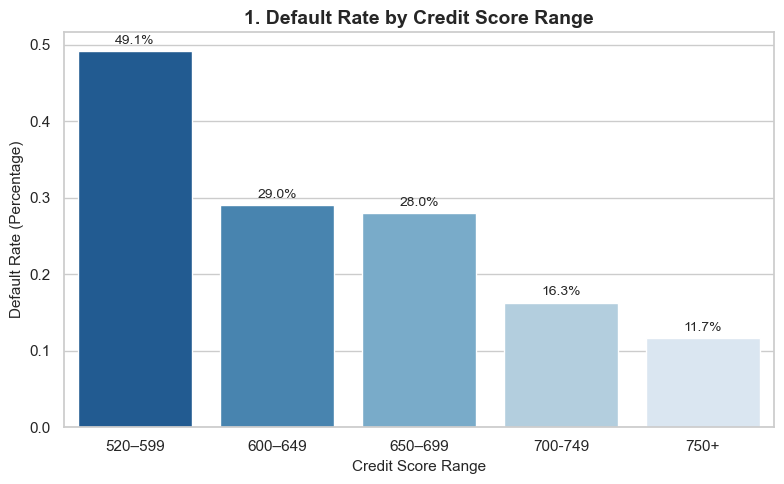

In [338]:
# Data Aggregation : Count the average of credit score bucket
cs_default = (
    df3.groupby("credit_score_bucket", observed = False)["defaulted"]
    .mean()
    .reset_index()
)

# Create separate figure
plt.figure(figsize = (8, 5))
sns.set_theme(style = "whitegrid")

# 3. Plot Bar Chart
ax1 = sns.barplot(
    data = cs_default,
    x = "credit_score_bucket",
    y = "defaulted",
    hue = "credit_score_bucket",
    legend = False,
    palette = "Blues_r",
)

# 4. Styling & Labeling
plt.title(
    "1. Default Rate by Credit Score Range", fontsize = 14, fontweight = "bold"
)
plt.xlabel("Credit Score Range", fontsize = 11)
plt.ylabel("Default Rate (Percentage)", fontsize = 11)

# Add labels percentage
for p in ax1.patches:
    ax1.annotate(
        f"{p.get_height()*100:.1f}%",
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha = "center",
        va = "bottom",
        fontsize = 10,
        xytext = (0, 3),
        textcoords = "offset points",
    )

plt.tight_layout()
plt.show()

In [320]:
# DTI Ratio VS Default Status

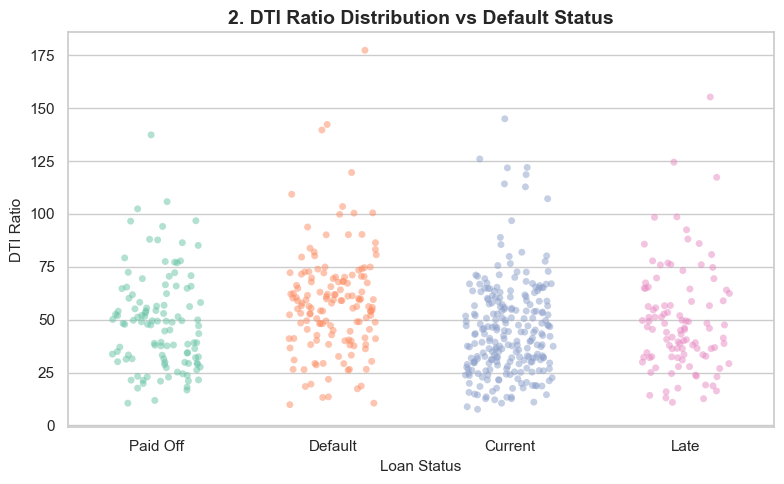

In [331]:
# Create figure separate
plt.figure(figsize=(8, 5))

# Plot Strip Plot with Jitter to make the dots spread out
sns.stripplot(
    data=df3,
    x="loan_status",
    y="dti_ratio",
    hue="loan_status",
    legend=False,
    palette="Set2",
    jitter=0.25,
    alpha=0.5,
)

# Styling
plt.title("2. DTI Ratio Distribution vs Default Status", fontsize=14, fontweight="bold")
plt.xlabel("Loan Status", fontsize=11)
plt.ylabel("DTI Ratio", fontsize=11)

plt.tight_layout()
plt.show()

In [329]:
# Default Rate by Loan Purpose

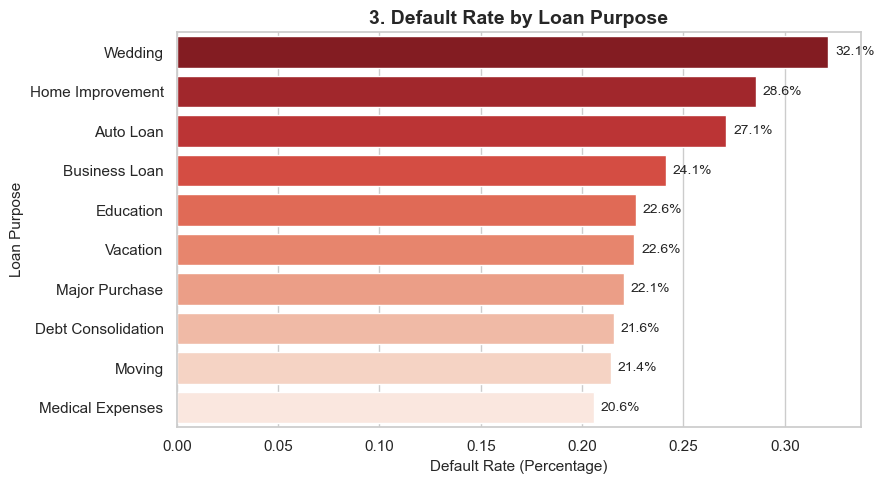

In [332]:
# Data Aggregation & Sort by Default Rate Descending
purpose_default = (
    df3.groupby("loan_purpose", observed = False)["defaulted"]
    .mean()
    .reset_index()
    .sort_values(by = "defaulted", ascending=False)
)

# Create figure separate
plt.figure(figsize = (9, 5))

# Plot Bar Chart Horizontal
ax3 = sns.barplot(
    data = purpose_default,
    x = "defaulted",
    y = "loan_purpose",
    hue = "loan_purpose",
    legend = False,
    palette = "Reds_r",
)

# Styling & Labeling
plt.title("3. Default Rate by Loan Purpose", fontsize = 14, fontweight = "bold")
plt.xlabel("Default Rate (Percentage)", fontsize = 11)
plt.ylabel("Loan Purpose", fontsize = 11)

# Add label percentage 
for p in ax3.patches:
    ax3.annotate(
        f"{p.get_width()*100:.1f}%",
        (p.get_width(), p.get_y() + p.get_height() / 2.0),
        ha = "left",
        va = "center",
        fontsize = 10,
        xytext = (5, 0),
        textcoords = "offset points",
    )

plt.tight_layout()
plt.show()

In [324]:
# Combined All Visualizations

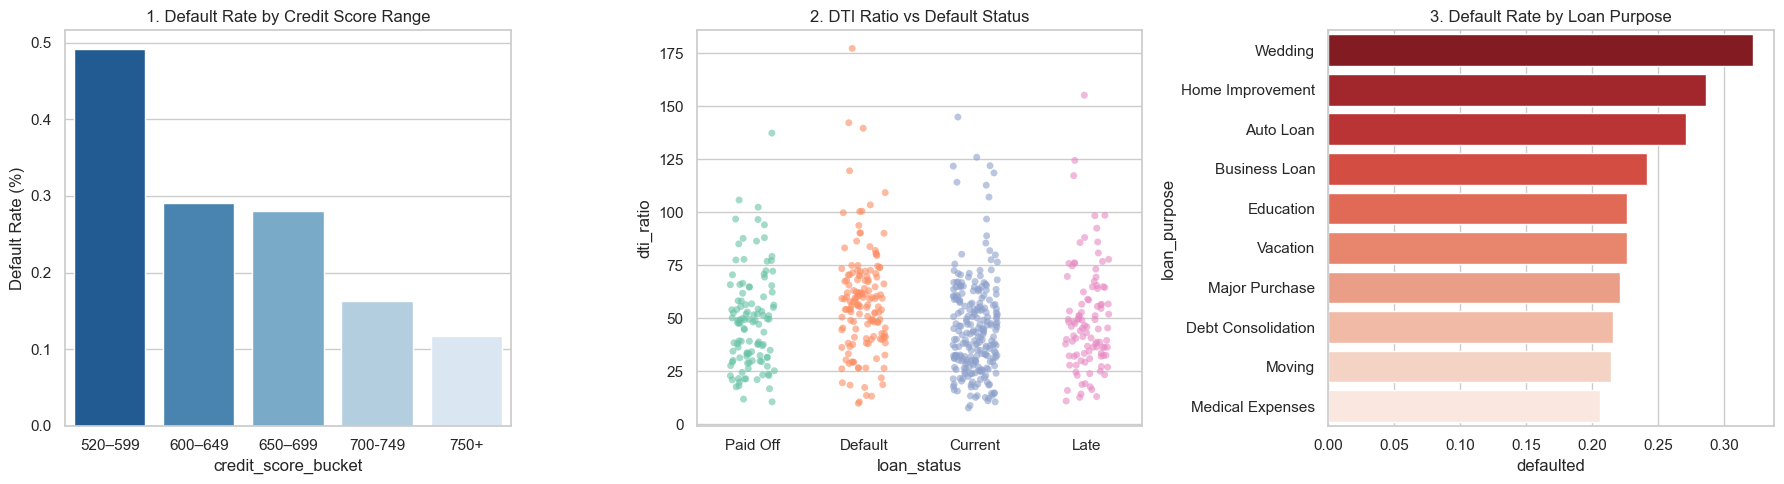

In [339]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Chart: Default Rate by Credit Score Range (Tambahkan observed=False & hue/legend=False)
cs_default = (
    df3.groupby("credit_score_bucket", observed = False)["defaulted"]
    .mean()
    .reset_index()
)
sns.barplot(
    data=cs_default,
    x = "credit_score_bucket",
    y = "defaulted",
    hue = "credit_score_bucket",  # Solusi Seaborn warning
    legend = False,  # Sembunyikan legenda berulang
    palette = "Blues_r",
    ax=axes[0],
)
axes[0].set_title("1. Default Rate by Credit Score Range")
axes[0].set_ylabel("Default Rate (%)")

# 2. Chart: DTI vs Default Status
sns.stripplot(
    data=df3,
    x = "loan_status",
    y = "dti_ratio",
    hue = "loan_status",  # Solusi Seaborn warning
    legend = False,
    palette = "Set2",
    jitter = 0.2,
    alpha = 0.6,
    ax = axes[1],
)
axes[1].set_title("2. DTI Ratio vs Default Status")

# 3. Chart: Default Rate by Loan Purpose
purpose_default = (
    df3.groupby("loan_purpose", observed = False)["defaulted"]
    .mean()
    .reset_index()
    .sort_values(by = "defaulted", ascending = False)
)
sns.barplot(
    data = purpose_default,
    x = "defaulted",
    y = "loan_purpose",
    hue = "loan_purpose", 
    legend = False,
    palette = "Reds_r",
    ax = axes[2],
)
axes[2].set_title("3. Default Rate by Loan Purpose")

plt.tight_layout()
plt.show()

In [ ]:
# 5. Recommendations

## Executive Recommendations for Underwriting Team

Based on the statistical analysis, $p\text{-value}$ hypothesis testing, and risk profiling conducted on the dataset (`df3`), i recommend that the Underwriting Team establish automated approval/rejection rules based on the following **Top 3 Risk Factors**:

---

### **Top 3 Risk Factors & Threshold Recommendations**

1. **Minimum Credit Score Threshold ($\ge 650$)**
   * **Data Finding:** Exhibits the strongest negative correlation with default ($r = -0.2864, p = 0.0000$). Segment analysis indicates that borrowers with credit scores below 650 experience a severe spike in default rates compared to higher-tier score buckets.
   * **Business Recommendation:** Set a strict minimum cutoff at **Credit Score $\ge 650$**. Applicants falling below this limit should be flagged for **Auto-Rejection** to mitigate the primary driver of non-performing loans.

2. **Maximum Debt-to-Income / DTI Ratio Threshold ($\le 40\%$)**
   * **Data Finding:** Exhibits a statistically significant positive correlation ($r = +0.0987, p = 0.0155$). Profiling shows that default probabilities rise significantly once a borrower’s monthly debt obligations exceed $40\%$ of their total income.
   * **Business Recommendation:** Establish a policy cap at **DTI Ratio $\le 40\%$** ($0.40$). Applicants with a DTI ratio above $40\%$ should require manual review, lower principal loan limits, or a qualified guarantor.

3. **Maximum Interest Rate Cap ($\le 15\%$)**
   * **Data Finding:** Exhibits a significant positive correlation ($r = +0.1989, p = 0.0000$). Excessively high interest rates disproportionately increase the borrower's monthly financial burden (*Risk-Based Pricing Trap*).
   * **Business Recommendation:** Implement a maximum standard rate cap at **Interest Rate $\le 15\%$** ($0.15$). Any high-risk loan requiring an interest rate above $15\%$ must undergo secondary approval by the Risk Committee (*Manual Underwriting Review*).

> **Variable Elimination Note:** The `loan_amount` variable has been **excluded** from the primary rejection criteria because it is not statistically significant ($p = 0.6576 > 0.05$).

---


In [341]:
df3.to_csv("loan_data_cleaned.csv", index=False)
print("Worked!")

Worked!
